# Stage 4b: Top words and phrases for high vs low ratings, per category
Reads the 900k-review sample (`MARTS.ML_DATASET`) and finds the words and two-word phrases most tied to **high (4-5 star)** and **low (1-2 star)** reviews in each category. 3-star reviews are left out here because they are ambiguous.

**Method.** For every word or phrase we compute a *log-odds z-score* (with an informative prior, Monroe et al. 2008). Unlike raw counts, it does not just return "the", "book", and "movie". A large positive score means the term is distinctive for high ratings, a large negative score means distinctive for low ratings. Each review counts a term once.

**Output:** charts in `reports/figures/`, tables in `reports/tables/`.

## 1. Connect

In [1]:
import getpass
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import snowflake.connector

ACCOUNT   = "SDTPFIN-KG72944"
USER      = "XIEZUOYE33@GMAIL.COM"           # each teammate uses their own Snowflake user
ROLE      = "PROJECT_ROLE"
WAREHOUSE = "COMPUTE_WH"
DB        = "DATA226GROUPPROJECT"

CATEGORIES = ["Books", "Music", "Video_DVD", "Digital_Ebook"]
COLORS = {"Books": "#0072B2", "Music": "#E69F00", "Video_DVD": "#009E73", "Digital_Ebook": "#CC79A7"}

FIG_DIR, TAB_DIR = Path("reports/figures"), Path("reports/tables")
FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)

conn = snowflake.connector.connect(
    account=ACCOUNT, user=USER,
    password=getpass.getpass("Snowflake password or token: "),
    role=ROLE, warehouse=WAREHOUSE, database=DB,
)
cur = conn.cursor()

def q(sql):
    """Run a query and return a pandas DataFrame with numeric columns converted."""
    cur.execute(sql)
    df = pd.DataFrame(cur.fetchall(), columns=[c[0].lower() for c in cur.description])
    for col in df.columns:
        if df[col].dtype == object:
            try:
                df[col] = pd.to_numeric(df[col])
            except (ValueError, TypeError):
                pass
    return df

def save_fig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150)
    plt.show()

def save_table(df, name, index=True):
    df.to_csv(TAB_DIR / f"{name}.csv", index=index)

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
print(q("SELECT CURRENT_USER(), CURRENT_ROLE()").iloc[0].tolist())

['xiezuoye33', 'PROJECT_ROLE']


## 2. Settings and helper functions

In [2]:
from collections import Counter
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS

ML = f"{DB}.MARTS.ML_DATASET"

MAX_DOCS_PER_CATEGORY = 150_000   # lower this if your laptop runs out of memory
MIN_DOC_FREQ   = 30               # ignore terms that appear in fewer than 30 reviews
PRIOR_STRENGTH = 500              # smoothing strength; higher = more cautious about rare terms
TOP_N = 15                        # terms to show per chart
LOW, HIGH = (1, 2), (4, 5)

# Keep negations: "not", "no", "never" matter a lot for sentiment
STOP = sorted(set(ENGLISH_STOP_WORDS) - {"not", "no", "never", "nothing", "nor", "cannot", "without"})

def log_odds_z(c_hi, c_lo, a0):
    """z-score per term. Positive = high-rating term, negative = low-rating term."""
    prior = c_hi + c_lo
    alpha = a0 * prior / prior.sum()
    n_hi, n_lo = c_hi.sum(), c_lo.sum()
    d_hi = np.log((c_hi + alpha) / (n_hi + a0 - c_hi - alpha))
    d_lo = np.log((c_lo + alpha) / (n_lo + a0 - c_lo - alpha))
    var = 1.0 / (c_hi + alpha) + 1.0 / (c_lo + alpha)
    return (d_hi - d_lo) / np.sqrt(var)

## 3. Score every term, one category at a time
Takes a few minutes per category.

In [3]:
results = {}
for cat in CATEGORIES:
    df = q(f"SELECT star_rating, review_text FROM {ML} WHERE category = '{cat}' AND star_rating IN (1, 2, 4, 5)")
    if len(df) > MAX_DOCS_PER_CATEGORY:
        df = df.sample(MAX_DOCS_PER_CATEGORY, random_state=42)
    is_low = df["star_rating"].isin(LOW).values

    vec = CountVectorizer(lowercase=False, stop_words=STOP, ngram_range=(1, 2), min_df=MIN_DOC_FREQ,
                          binary=True, token_pattern=r"(?u)\b[a-z][a-z']+\b")
    X = vec.fit_transform(df["review_text"])
    c_hi = np.asarray(X[~is_low].sum(axis=0)).ravel().astype(float)
    c_lo = np.asarray(X[is_low].sum(axis=0)).ravel().astype(float)

    res = pd.DataFrame({
        "term": vec.get_feature_names_out(),
        "z": log_odds_z(c_hi, c_lo, PRIOR_STRENGTH),
        "reviews_high": c_hi.astype(int),
        "reviews_low": c_lo.astype(int),
        "pct_of_high_reviews": c_hi / (~is_low).sum() * 100,
        "pct_of_low_reviews": c_lo / is_low.sum() * 100,
    }).sort_values("z", ascending=False).reset_index(drop=True)
    results[cat] = res
    print(f"{cat}: {len(df):,} reviews ({is_low.sum():,} low / {(~is_low).sum():,} high), {len(res):,} terms scored")
    del X, df

Books: 142,067 reviews (20,087 low / 121,980 high), 38,806 terms scored
Music: 150,000 reviews (12,069 low / 137,931 high), 34,477 terms scored
Video_DVD: 150,000 reviews (17,239 low / 132,761 high), 29,593 terms scored
Digital_Ebook: 150,000 reviews (15,951 low / 134,049 high), 25,165 terms scored


## 4. Top terms per category

In [4]:
for cat in CATEGORIES:
    res = results[cat]
    cols = ["term", "z", "pct_of_high_reviews", "pct_of_low_reviews"]
    print(f"\n===== {cat}: terms for HIGH ratings (4-5 stars) =====")
    print(res.head(TOP_N)[cols].round(2).to_string(index=False))
    print(f"\n===== {cat}: terms for LOW ratings (1-2 stars) =====")
    print(res.tail(TOP_N).iloc[::-1][cols].round(2).to_string(index=False))


===== Books: terms for HIGH ratings (4-5 stars) =====
            term     z  pct_of_high_reviews  pct_of_low_reviews
           great 39.17                27.29               12.49
       excellent 34.54                11.30                2.15
       wonderful 30.69                 9.37                2.12
          highly 28.49                 8.95                2.52
            life 27.83                19.66               10.86
            best 27.18                16.92                8.91
            easy 25.04                 8.48                3.11
      great book 24.69                 5.64                0.93
            love 23.21                14.36                8.09
highly recommend 20.80                 4.02                0.41
           loved 20.22                 5.93                2.32
         amazing 19.42                 3.92                0.99
       beautiful 19.26                 4.39                1.38
       recommend 19.13                11.79      

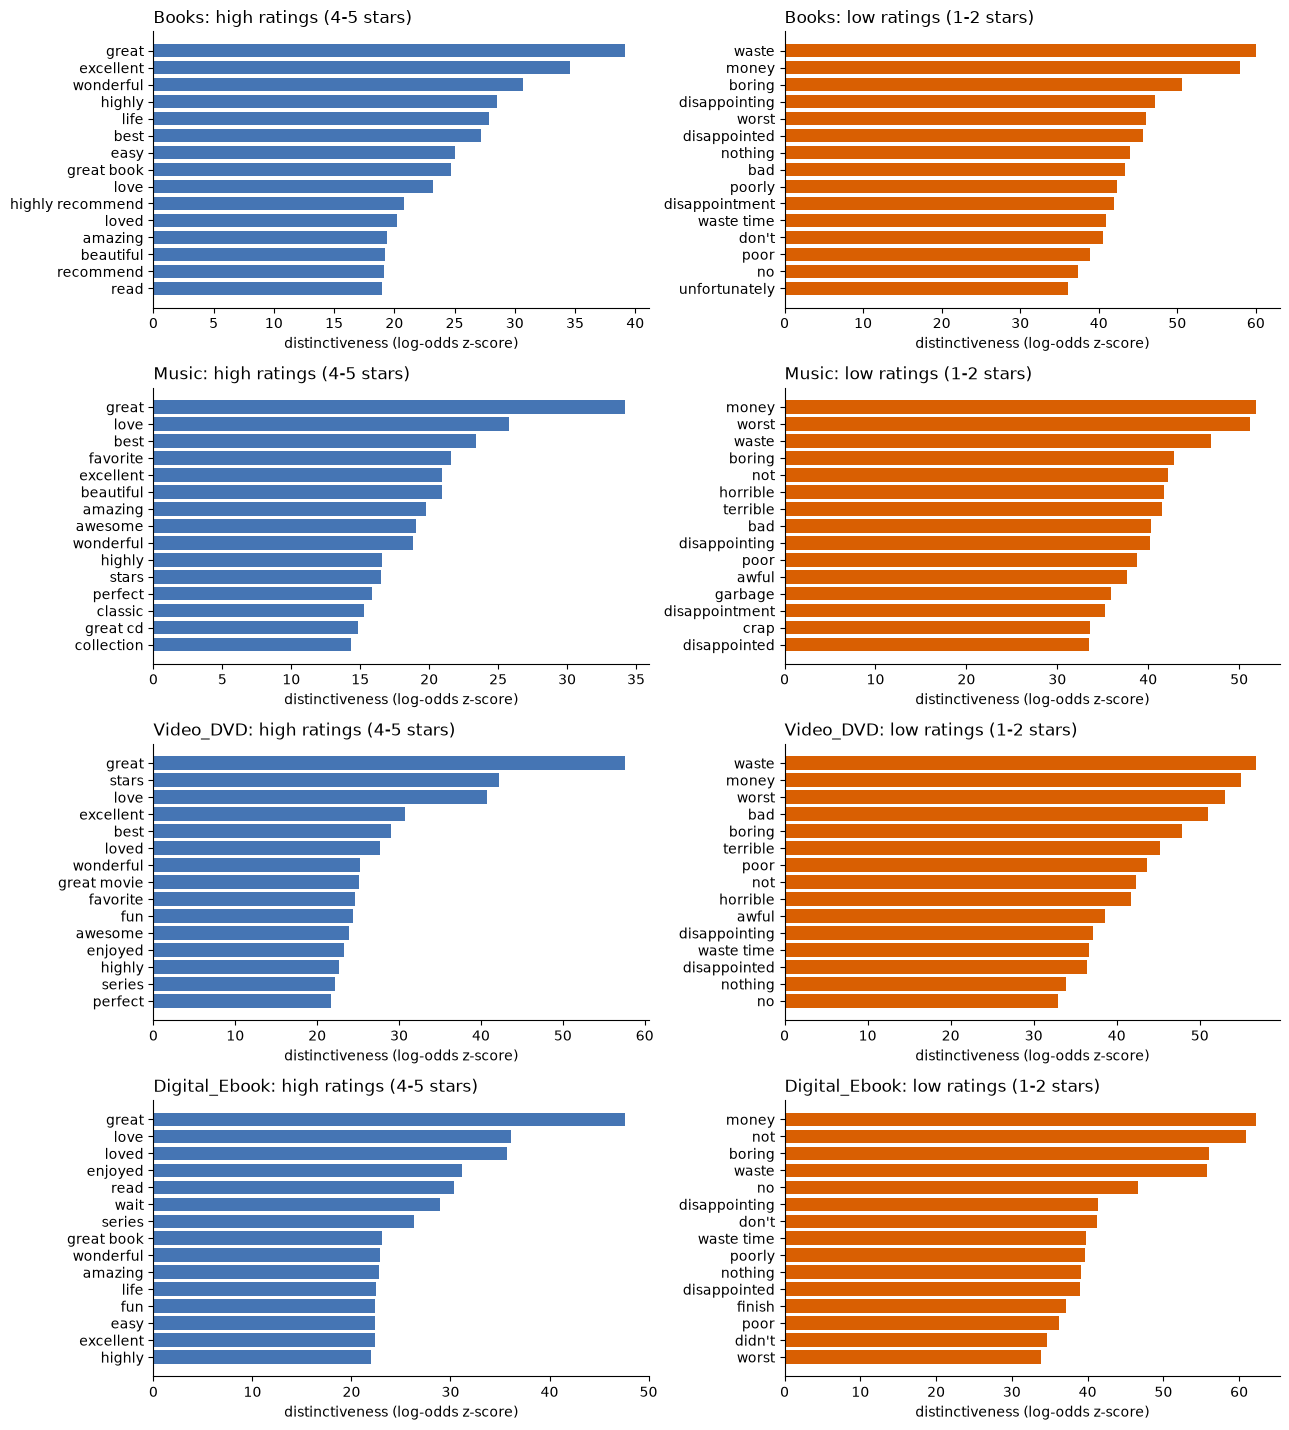

In [5]:
fig, axes = plt.subplots(len(CATEGORIES), 2, figsize=(13, 3.6 * len(CATEGORIES)))
for row, cat in enumerate(CATEGORIES):
    res = results[cat]
    hi = res.head(TOP_N).iloc[::-1]     # barh draws the first row at the bottom,
    lo = res.tail(TOP_N)                # so the strongest term ends up at the top
    axes[row, 0].barh(hi["term"], hi["z"], color="#4575b4")
    axes[row, 1].barh(lo["term"], -lo["z"], color="#d95f02")
    axes[row, 0].set_title(f"{cat}: high ratings (4-5 stars)", loc="left")
    axes[row, 1].set_title(f"{cat}: low ratings (1-2 stars)", loc="left")
    axes[row, 0].set_xlabel("distinctiveness (log-odds z-score)")
    axes[row, 1].set_xlabel("distinctiveness (log-odds z-score)")
save_fig("top_terms_by_category")

## 5. Universal vs category-specific language
This answers the project question directly: which words signal rating in **every** category, and which only in one? We take each category's 100 most distinctive terms and compare.

In [6]:
TOPK = 100
top_hi = {c: list(results[c].head(TOPK)["term"]) for c in CATEGORIES}
top_lo = {c: list(results[c].tail(TOPK).iloc[::-1]["term"]) for c in CATEGORIES}

def universal_and_specific(top):
    cnt = Counter(t for terms in top.values() for t in terms)
    universal = [t for t, k in cnt.items() if k >= 3]
    specific = {c: [t for t in terms if cnt[t] == 1][:12] for c, terms in top.items()}
    return universal, specific

for label, top in [("HIGH ratings", top_hi), ("LOW ratings", top_lo)]:
    universal, specific = universal_and_specific(top)
    print(f"\n######## {label} ########")
    print(f"Terms in the top {TOPK} of at least 3 of 4 categories ({len(universal)}):")
    print("  ", ", ".join(universal[:40]))
    for c in CATEGORIES:
        print(f"Only in {c}: ", ", ".join(specific[c]))

def overlap_table(top):
    return pd.DataFrame([[len(set(top[a]) & set(top[b])) for b in CATEGORIES] for a in CATEGORIES],
                        index=CATEGORIES, columns=CATEGORIES)

print(f"\nShared terms between categories (out of {TOPK}), HIGH ratings:")
print(overlap_table(top_hi).to_string())
print(f"\nShared terms between categories (out of {TOPK}), LOW ratings:")
print(overlap_table(top_lo).to_string())


######## HIGH ratings ########
Terms in the top 100 of at least 3 of 4 categories (43):
   great, excellent, wonderful, highly, life, best, easy, love, highly recommend, loved, amazing, beautiful, recommend, family, fun, favorite, recommended, heart, enjoyed, world, unique, highly recommended, fantastic, perfect, gives, brings, powerful, enjoyable, gift, beautifully, outstanding, can't wait, awesome, thank, job, incredible, classic, superb, story, brilliant
Only in Books:  provides, excellent book, best book, resource, helped, home, informative, wonderful book, helps, book read, explains, illustrations
Only in Music:  great cd, great album, love cd, great music, cd great, rocks, solid, masterpiece, rare, blues, piano, jazz
Only in Video_DVD:  great movie, season, love movie, shows, movie great, hilarious, price, condition, arrived, good movie, christmas, loved movie
Only in Digital_Ebook:  wait, forward, good read, fast, can't, twists, look forward, looking forward, mystery, love stor

In [7]:
for cat in CATEGORIES:
    res = results[cat]
    save_table(pd.concat([res.head(200), res.tail(200)]).drop_duplicates("term"), f"top_terms_{cat}", index=False)
save_table(overlap_table(top_hi), "term_overlap_high")
save_table(overlap_table(top_lo), "term_overlap_low")
conn.close()
print("Saved tables:", sorted(p.name for p in TAB_DIR.glob("top_terms_*.csv")))

Saved tables: ['top_terms_Books.csv', 'top_terms_Digital_Ebook.csv', 'top_terms_Music.csv', 'top_terms_Video_DVD.csv']


**Done with 4b.** The overlap tables are a first quantitative answer to the project question: how much of the rating language is shared across categories? Stage 5 trains the models and tests that for real.